# Lab 1.2 · LLM inference mechanics

**15–20 minutes · CPU · Python standard library**

## How to work through this notebook

Read the worked example, run the setup, then complete the exercises in order. Replace each `return None` placeholder with your code and run the cell below to check your result. Use the wrap-up to explain the output in your own words.

## Concepts and worked example

A decoder generates text one token at a time. A token is an integer ID representing a piece of text. A forward pass produces scores for possible next tokens, and greedy selection picks the highest score.

**Prefill** processes the entire prompt and gives you the scores used to pick the first generated token. In a real transformer, this pass also saves attention keys and values for the prompt positions in a **KV cache**. **Decode** then processes the latest generated token, reads the cached state, and picks another token. The last generated token has yet to enter the cache until it is fed back in.

For a two-token prompt and three generated tokens, the cached path processes input lengths `2 + 1 + 1 = 4`. Recomputing from scratch processes `2 + 3 + 4 = 9`. Both should generate the same tokens. The notebook stores IDs as a stand-in for key/value tensors and counts IDs passed to the model. Real attention still reads earlier cache entries. The toy predictor also scans the stored IDs when it computes a score. The counter tracks only new IDs passed into its interface, so it is useful for tracing reuse and cannot estimate elapsed time.

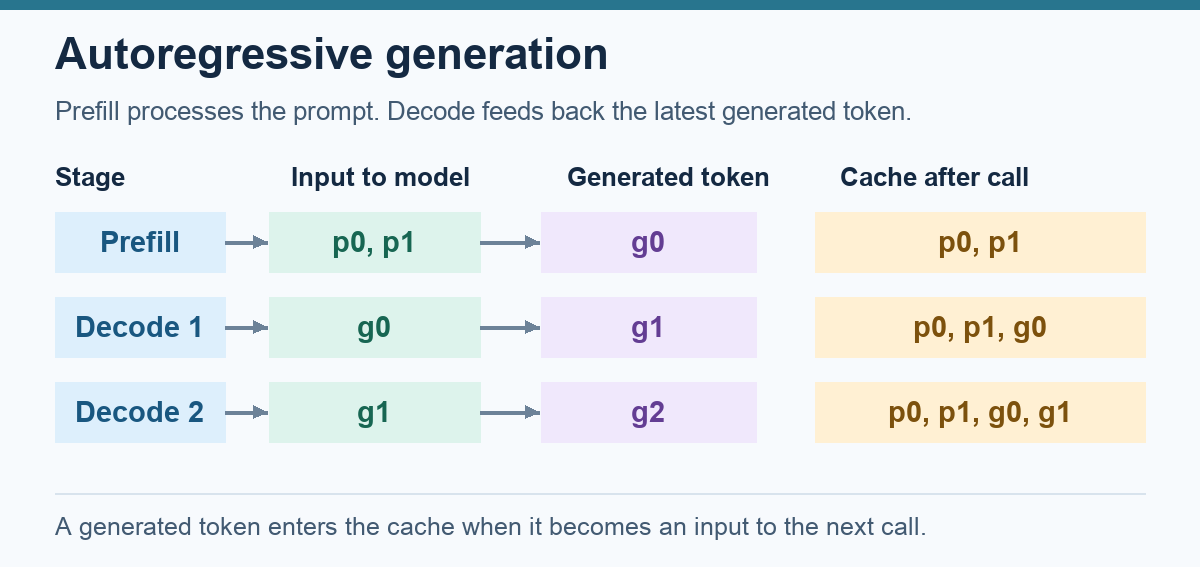

## Exercise map

1. **Prefill once** — Pass the entire prompt into a fresh cache, then choose the first generated token from the scores.
2. **Decode and compare** — Build the cached loop, then compare its token sequence and work count with the supplied recomputation loop.

[Open the lab guide](README.md) for the exercise checklist.

In [ ]:
# A stateful stand-in with a fixed vocabulary of eight token IDs.
def forward(new_ids, cache):
    cache.extend(new_ids)
    scores = [-((i - (sum(cache) + len(cache)) % 8) ** 2) for i in range(8)]
    return scores

def greedy(scores):
    return max(range(len(scores)), key=scores.__getitem__)

prompt = [2, 1, 4]

## Exercise 1. Prefill once

Predict the cache length and the first token ID. Call forward once with the complete prompt and an empty cache. Return the greedy token and the cache.

**Implementation hint** — Create a fresh list inside prefill. The forward function appends its input IDs to that list.

**After running the check** — Inspect the returned cache and first token separately. The cache contains the prompt while the token is ready for the next call.

In [ ]:
def prefill(prompt):
    return None

In [ ]:
first = prefill(prompt)
if first is not None:
    token, cache = first
    assert (token, cache) == (2, [2, 1, 4])
    assert cache is not prompt
    print("PASS — first token and cache:", first)

### Read the result

Look at the first generated ID and cache separately. The generated ID appears in the cache only after it is fed back.

## Exercise 2. Decode and compare

Complete the cached path. Prefill once, then pass only the previous output token into each decode call. The prompt and step count are nonempty. Predict how many input token IDs each path will process.

**Implementation hint** — Start with the token and cache returned by prefill. Each remaining step feeds a list containing just the last output token.

**After running the check** — Identical generated IDs establish that reuse preserved the result. Compare the input counts for one output token and for a longer generation.

In [ ]:
def generate_cached(prompt, steps):
    # Return (generated IDs, number of token IDs passed to forward).
    return None

In [ ]:
def generate_recomputed(prompt, steps):
    generated = []
    work = 0
    for _ in range(steps):
        full_input = prompt + generated
        generated.append(greedy(forward(full_input, [])))
        work += len(full_input)
    return generated, work

for steps in (1, 4, 8):
    reference, recomputed_work = generate_recomputed(prompt, steps)
    cached = generate_cached(prompt, steps)
    if cached is not None:
        generated, cached_work = cached
        assert generated == reference
        assert cached_work == len(prompt) + steps - 1
        print(steps, "output tokens:", cached_work, "cached vs",
              recomputed_work, "recomputed input IDs")
if generate_cached(prompt, 4) is not None:
    print("PASS — identical output IDs")

### Read the result

The generated sequences should match. The input-ID count isolates repeated input processing and leaves out the cost of reading prior state.

## Compare your results

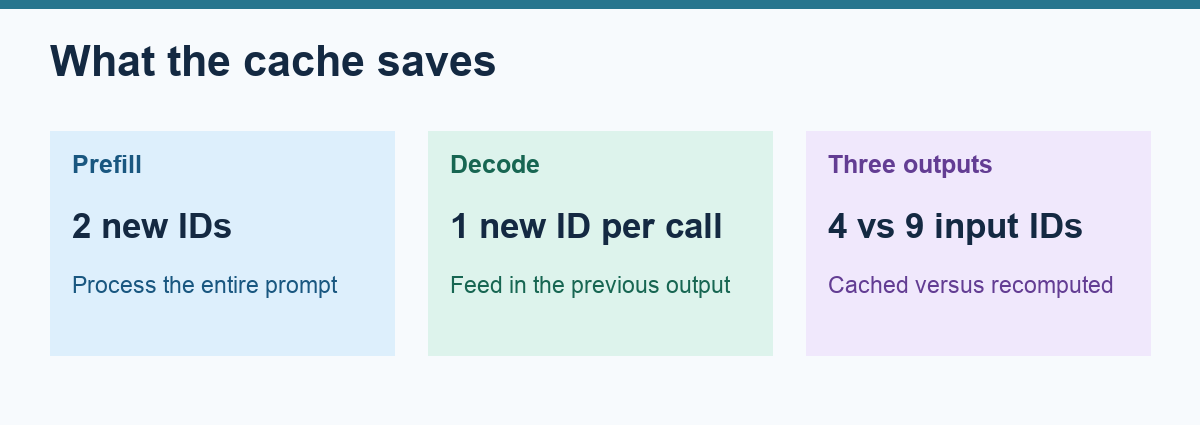

## Optional extension · From logits to the next input

Kiely breaks generation into formatting and tokenizing the request, running the model, and selecting a token from the resulting logits. The lab starts after tokenization and uses greedy selection. Sampling can retain several candidates, and a stop token or a token budget can end the decode loop.

Compare greedy selection with sampling restricted to the top two candidates. Predict which IDs remain eligible and explain which selected ID would be fed into the next decode call.

**Reading** · Philip Kiely, *Inference Engineering*, §2.2, pp. 46–49.

In [ ]:
from math import exp

scores = [0.0, 2.0, 1.0]
eligible = sorted(range(len(scores)), key=scores.__getitem__, reverse=True)[:2]
weights = [exp(scores[i] - scores[eligible[0]]) for i in eligible]
probabilities = [weight / sum(weights) for weight in weights]
assert greedy(scores) == 1 and eligible == [1, 2]
print("Greedy:", greedy(scores), "Top-two distribution:", dict(zip(eligible, probabilities)))

## Wrap-up

Why do both paths process the same number of input IDs for the first token? Double the prompt length and rerun. Which count grows faster as you increase the output length?

## Optional system exercise · A decode budget that matches the request

Consider two requests with the same prompt but budgets of 1 and 64 generated tokens. Predict how many times each request enters decode after prefill. Then vary the notebook's step count and explain why counting only input IDs misses the cost of scanning cached state.